### Etapa 1 – Carregando a base de dados ###

In [3]:

# ==========================================
# PROJETO: CALIFORNIA HOUSING
# Previsão do valor médio das residências
# ==========================================

# 1. Importando as bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

# 2. Carregando a base de dados

dados = fetch_california_housing(as_frame=True)

# 3. Transformando os dados em DataFrame

df = dados.frame

# 4. Visualizando as primeiras linhas

print("PRIMEIRAS LINHAS DA BASE DE DADOS:")
print(df.head())


PRIMEIRAS LINHAS DA BASE DE DADOS:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [4]:

# ==========================================
# ETAPA 3 - ANALISE EXPLORATORIA DOS DADOS
# ==========================================

# 3.1 - Dimensoes da base de dados

print("\nDIMENSOES DA BASE:")
print(df.shape)

# 3.2 - Informacoes gerais das colunas

print("\nINFORMACOES DA BASE:")
df.info()

# 3.3 - Nomes das colunas

print("\nCOLUNAS DISPONIVEIS:")
print(df.columns.tolist())



DIMENSOES DA BASE:
(20640, 9)

INFORMACOES DA BASE:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

COLUNAS DISPONIVEIS:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


In [5]:

# 3.4 - Estatisticas descritivas

print("\nESTATISTICAS DESCRITIVAS:")
print(df.describe())



ESTATISTICAS DESCRITIVAS:
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
25%        2.563400     18.000000      4.440716      1.006079    787.000000   
50%        3.534800     29.000000      5.229129      1.048780   1166.000000   
75%        4.743250     37.000000      6.052381      1.099526   1725.000000   
max       15.000100     52.000000    141.909091     34.066667  35682.000000   

           AveOccup      Latitude     Longitude   MedHouseVal  
count  20640.000000  20640.000000  20640.000000  20640.000000  
mean       3.070655     35.631861   -119.569704      2.068558  
std       10.386050      2.135952      2.003532      1.153956  
min  

In [6]:

# 3.5 - Verificando valores ausentes

print("\nVALORES AUSENTES:")
print(df.isnull().sum())

# 3.6 - Verificando registros duplicados

print("\nREGISTROS DUPLICADOS:")
print(df.duplicated().sum())



VALORES AUSENTES:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

REGISTROS DUPLICADOS:
0


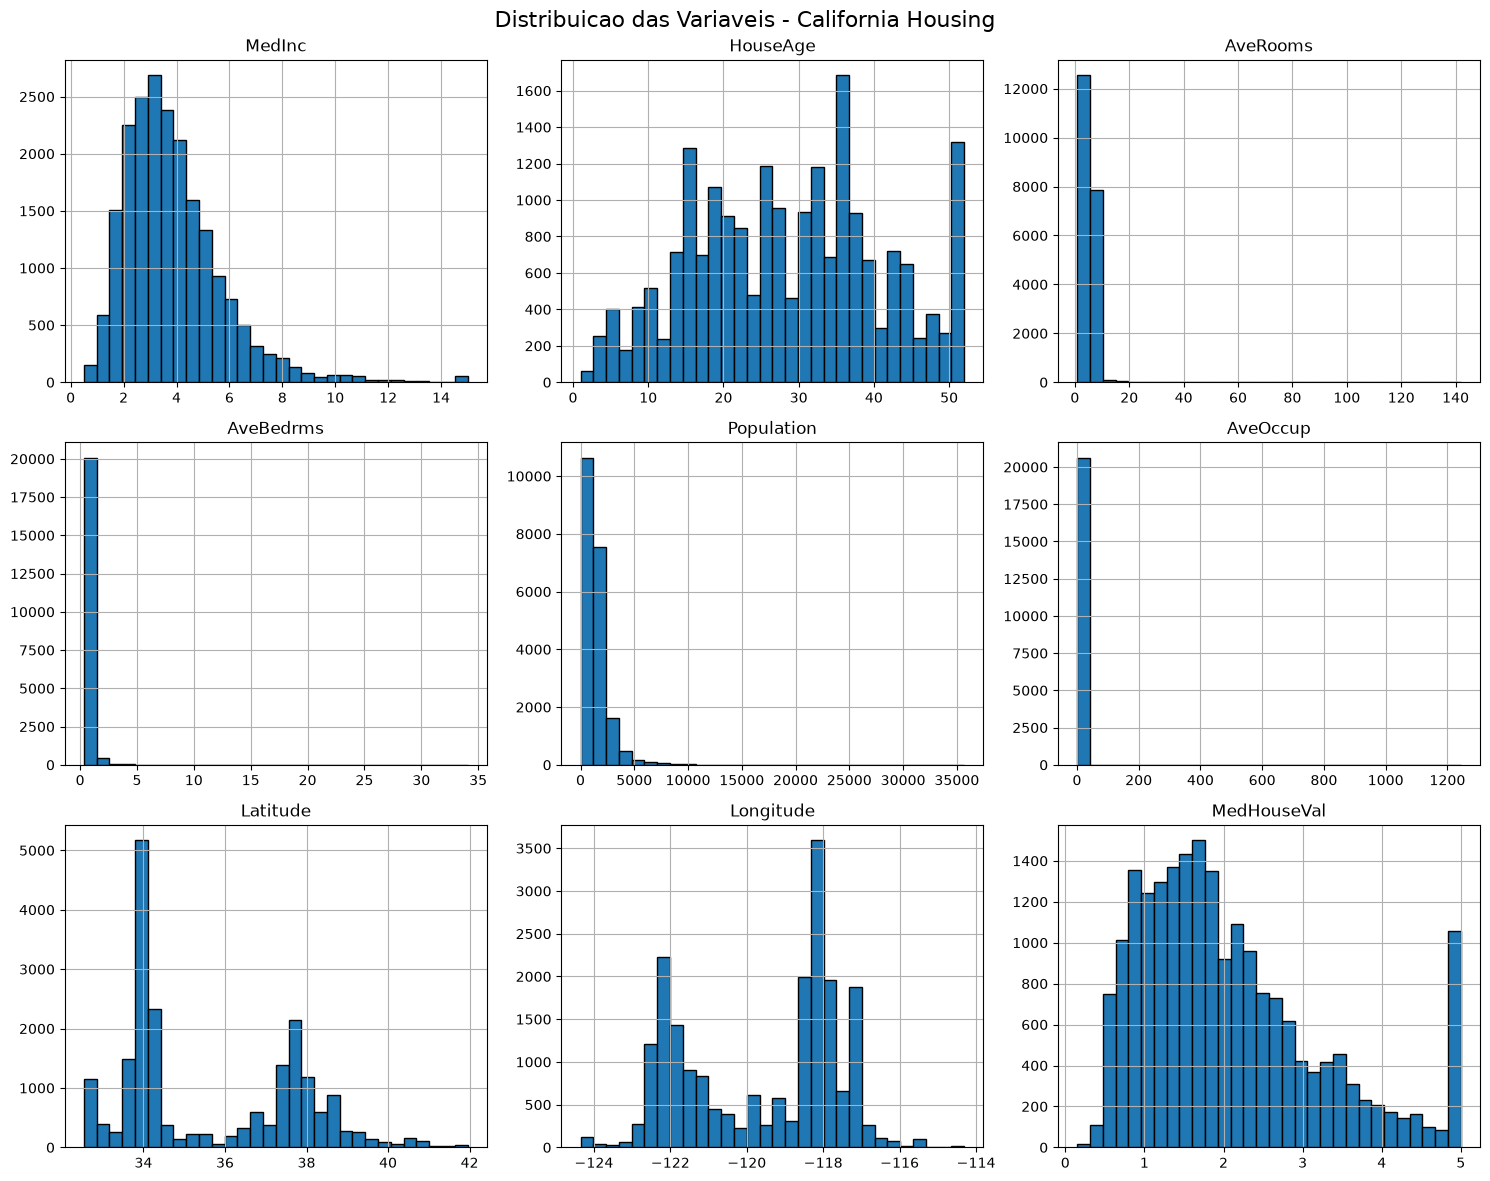

In [7]:

# ==========================================
# ETAPA 4 - VISUALIZACAO DOS DADOS
# ==========================================

# 4.1 - Histogramas das variaveis

df.hist(figsize=(15, 12), bins=30, edgecolor='black')

plt.suptitle(
    'Distribuicao das Variaveis - California Housing',
    fontsize=16
)

plt.tight_layout()
plt.show()


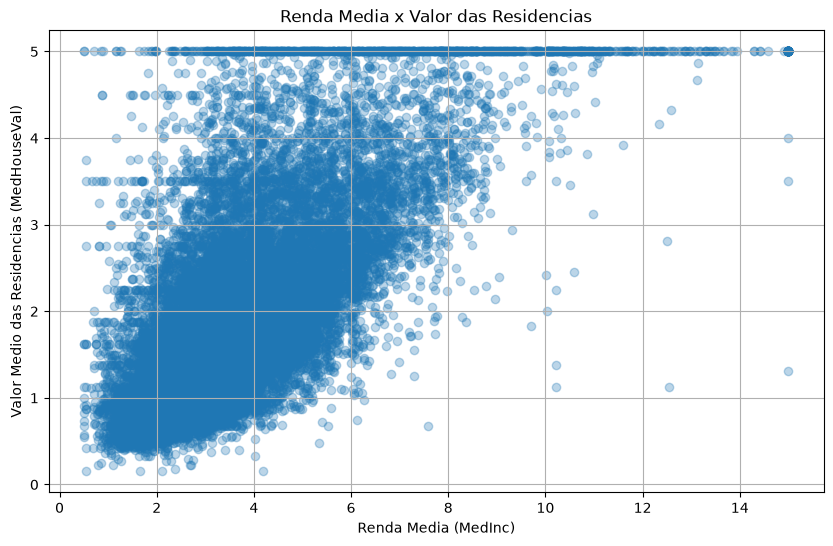

In [8]:

# 4.2 - Relacao entre renda e valor das residencias

plt.figure(figsize=(10, 6))

plt.scatter(
    df['MedInc'],
    df['MedHouseVal'],
    alpha=0.3
)

plt.title('Renda Media x Valor das Residencias')
plt.xlabel('Renda Media (MedInc)')
plt.ylabel('Valor Medio das Residencias (MedHouseVal)')

plt.grid(True)
plt.show()


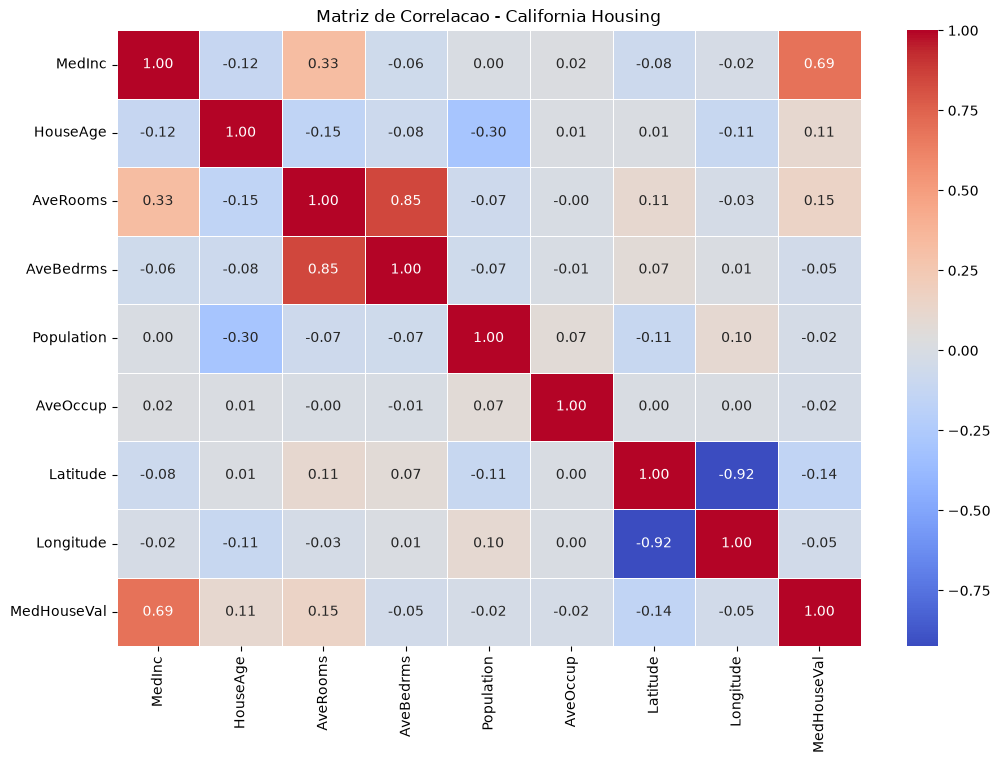

In [9]:

# 4.3 - Matriz de correlacao

plt.figure(figsize=(12, 8))

correlacao = df.corr()

sns.heatmap(
    correlacao,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Matriz de Correlacao - California Housing')

plt.show()


In [10]:

# ==========================================
# ETAPA 5 - PRE-PROCESSAMENTO
# ==========================================

# Separando as variaveis independentes (X)
X = df.drop('MedHouseVal', axis=1)

# Separando a variavel dependente (y)
y = df['MedHouseVal']

print("\nDIMENSOES DAS VARIAVEIS:")
print("X:", X.shape)
print("y:", y.shape)



DIMENSOES DAS VARIAVEIS:
X: (20640, 8)
y: (20640,)


In [11]:

from sklearn.model_selection import train_test_split

# Separando os dados em treinamento e teste

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nDIVISAO DOS DADOS:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)



DIVISAO DOS DADOS:
X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


In [12]:

# ==========================================
# ETAPA 6 - TREINAMENTO DOS MODELOS
# ==========================================

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Criando o modelo de Regressao Linear

modelo_linear = Pipeline([
    ('escalonamento', StandardScaler()),
    ('modelo', LinearRegression())
])

# Treinando o modelo

modelo_linear.fit(X_train, y_train)

print("\nMODELO DE REGRESSAO LINEAR TREINADO!")



MODELO DE REGRESSAO LINEAR TREINADO!


In [13]:

from sklearn.ensemble import RandomForestRegressor

# Criando o modelo Random Forest

modelo_floresta = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Treinando o modelo

modelo_floresta.fit(X_train, y_train)

print("MODELO RANDOM FOREST TREINADO!")


MODELO RANDOM FOREST TREINADO!


In [14]:

# ==========================================
# ETAPA 7 - AVALIACAO DOS MODELOS
# ==========================================

# Realizando previsoes

previsoes_linear = modelo_linear.predict(X_test)

previsoes_floresta = modelo_floresta.predict(X_test)

print("\nPREVISOES REALIZADAS COM SUCESSO!")



PREVISOES REALIZADAS COM SUCESSO!


In [15]:

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Avaliacao da Regressao Linear

mae_linear = mean_absolute_error(y_test, previsoes_linear)

rmse_linear = np.sqrt(
    mean_squared_error(y_test, previsoes_linear)
)

r2_linear = r2_score(y_test, previsoes_linear)


# Avaliacao do Random Forest

mae_floresta = mean_absolute_error(y_test, previsoes_floresta)

rmse_floresta = np.sqrt(
    mean_squared_error(y_test, previsoes_floresta)
)

r2_floresta = r2_score(y_test, previsoes_floresta)


# Exibindo os resultados

print("\nRESULTADOS - REGRESSAO LINEAR")

print("MAE:", round(mae_linear, 4))
print("RMSE:", round(rmse_linear, 4))
print("R2:", round(r2_linear, 4))


print("\nRESULTADOS - RANDOM FOREST")

print("MAE:", round(mae_floresta, 4))
print("RMSE:", round(rmse_floresta, 4))
print("R2:", round(r2_floresta, 4))



RESULTADOS - REGRESSAO LINEAR
MAE: 0.5332
RMSE: 0.7456
R2: 0.5758

RESULTADOS - RANDOM FOREST
MAE: 0.3277
RMSE: 0.506
R2: 0.8046


In [16]:

# ==========================================
# COMPARACAO FINAL DOS MODELOS
# ==========================================

comparacao = pd.DataFrame({
    'Modelo': ['Regressao Linear', 'Random Forest'],
    'MAE': [mae_linear, mae_floresta],
    'RMSE': [rmse_linear, rmse_floresta],
    'R2': [r2_linear, r2_floresta]
})

print("\nCOMPARACAO DOS MODELOS:")
print(comparacao.to_string(index=False))

# Identificando o melhor modelo pelo R2

if r2_floresta > r2_linear:
    print("\nMELHOR MODELO: RANDOM FOREST")
else:
    print("\nMELHOR MODELO: REGRESSAO LINEAR")



COMPARACAO DOS MODELOS:
          Modelo      MAE     RMSE       R2
Regressao Linear 0.533200 0.745581 0.575788
   Random Forest 0.327731 0.505986 0.804624

MELHOR MODELO: RANDOM FOREST



IMPORTANCIA DAS VARIAVEIS:
  Variavel  Importancia
    MedInc     0.524980
  AveOccup     0.138367
  Latitude     0.089035
 Longitude     0.088474
  HouseAge     0.054602
  AveRooms     0.044216
Population     0.030662
 AveBedrms     0.029663


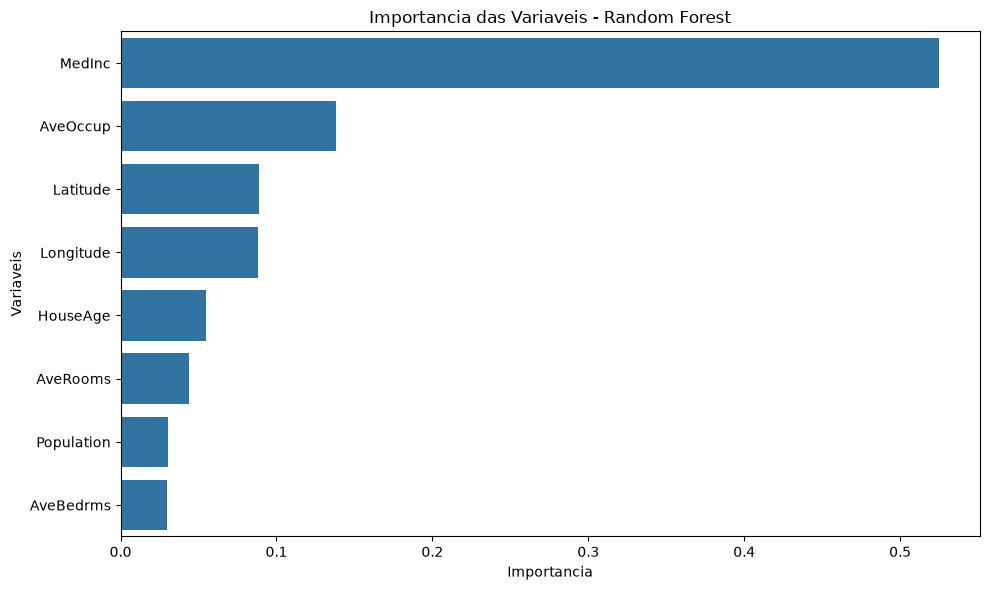

In [17]:

# ==========================================
# ETAPA EXTRA - IMPORTANCIA DAS VARIAVEIS
# ==========================================

importancias = modelo_floresta.feature_importances_

importancia_df = pd.DataFrame({
    'Variavel': X.columns,
    'Importancia': importancias
})

importancia_df = importancia_df.sort_values(
    by='Importancia',
    ascending=False
)

print("\nIMPORTANCIA DAS VARIAVEIS:")
print(importancia_df.to_string(index=False))

# Criando grafico

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importancia_df,
    x='Importancia',
    y='Variavel'
)

plt.title('Importancia das Variaveis - Random Forest')
plt.xlabel('Importancia')
plt.ylabel('Variaveis')

plt.tight_layout()
plt.show()
